# 01_01 Bernoulli and Binomial

**Learning objectives**
- Describe a Bernoulli trial and build the Binomial from n independent trials.
- Derive the Binomial PMF by a counting argument, and its mean, variance and PGF/MGF.
- Read how n and p change the shape, and use the normal approximation with continuity correction.
- Answer real planning questions (probabilities, quantiles) by hand, in code and by simulation.

**Prerequisites:** none (this is the first lesson of the book). Module 00 (foundations) is not written yet, so the recap below restates what we need.

## 1. Setup

All imports live in one cell. The random generator is seeded so the notebook is reproducible.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- A **random variable** $X$ assigns a number to each outcome of a random process.
- A **PMF** $P(X=k)$ gives the probability of each value of a discrete variable; the values sum to 1.
- The **CDF** is $F(k)=P(X\le k)$, a running total of the PMF.
- The **expected value** is $E[X]=\sum_k k\,P(X=k)$ and the **variance** is $\mathrm{Var}(X)=E[(X-E[X])^2]=E[X^2]-E[X]^2$.
- Two events are **independent** if $P(A\cap B)=P(A)P(B)$.

## 3. Intuition and story

A **Bernoulli trial** is one experiment with two outcomes: success (1) or failure (0). A visitor lands on a web shop and either buys (1) or leaves (0). A manufactured part is either defective (1) or fine (0). A coin lands heads (1) or tails (0).

Now repeat the trial **n times**, independently, each with the same success probability $p$. The number of successes $X$ is **Binomial(n, p)**. If 1,000 visitors each buy with probability 3.2 %, the number of orders per day is Binomial(1000, 0.032).

Two assumptions matter: trials are **independent** and **p is the same each time**. When either fails (for example, visitors influence each other), the Binomial is only an approximation.

## 4. Formal definition

**Bernoulli($p$)**: support $\{0,1\}$, parameter $p\in[0,1]$.
$$P(X=1)=p,\qquad P(X=0)=1-p,\qquad\text{or compactly}\quad P(X=x)=p^x(1-p)^{1-x}.$$

**Binomial($n,p$)**: support $\{0,1,\dots,n\}$, parameters $n\in\mathbb{N}$ (number of trials) and $p\in[0,1]$ (success probability).
$$P(X=k)=\binom{n}{k}p^k(1-p)^{n-k},\qquad F(k)=\sum_{j=0}^{k}\binom{n}{j}p^j(1-p)^{n-j}.$$

Binomial(1, p) is exactly Bernoulli(p).

## 5. Derivations

### 5.1 The PMF by counting
Take one specific sequence with $k$ successes and $n-k$ failures, for example S S F S F. By independence its probability is the product $p\cdot p\cdot(1-p)\cdot p\cdot(1-p)=p^k(1-p)^{n-k}$. Every sequence with $k$ successes has this same probability. The number of such sequences is the number of ways to choose which $k$ of the $n$ positions are successes, $\binom{n}{k}$. Adding them up gives the PMF.

### 5.2 Normalization
By the binomial theorem $(a+b)^n=\sum_k\binom{n}{k}a^kb^{n-k}$. With $a=p$, $b=1-p$:
$$\sum_{k=0}^{n}\binom{n}{k}p^k(1-p)^{n-k}=(p+1-p)^n=1.$$

### 5.3 Mean and variance via indicators
Write $X=B_1+\dots+B_n$ where each $B_i$ is Bernoulli($p$). For one Bernoulli: $E[B]=0\cdot(1-p)+1\cdot p=p$. Since $B^2=B$, $E[B^2]=p$ and $\mathrm{Var}(B)=p-p^2=p(1-p)$.
Expectation is linear, so $E[X]=np$. For independent variables variances add, so
$$E[X]=np,\qquad \mathrm{Var}(X)=np(1-p).$$

### 5.4 PGF and MGF
The probability generating function of one Bernoulli is $G_B(s)=E[s^B]=(1-p)+ps$. For independent sums the PGFs multiply:
$$G_X(s)=\big(1-p+ps\big)^n.$$
The MGF is $M_X(t)=E[e^{tX}]=G_X(e^t)=(1-p+pe^t)^n$. Differentiating: $M_X'(0)=n\,p\,e^0(1-p+p)^{n-1}=np$, which confirms the mean.

### 5.5 Mode, skewness, kurtosis
- **Mode:** $\lfloor (n+1)p\rfloor$ (two modes when $(n+1)p$ is an integer).
- **Skewness:** $\dfrac{1-2p}{\sqrt{np(1-p)}}$. Positive for $p<0.5$, zero at $p=0.5$, negative for $p>0.5$.
- **Excess kurtosis:** $\dfrac{1-6p(1-p)}{np(1-p)}$. Both are stated, not derived (standard result via the cumulant generating function $n\ln(1-p+pe^t)$).

## 6. Properties and relationships

- **Additivity:** if $X\sim\text{Bin}(n_1,p)$ and $Y\sim\text{Bin}(n_2,p)$ are independent, then $X+Y\sim\text{Bin}(n_1+n_2,p)$ (same $p$ required). Follows by multiplying PGFs.
- **Symmetry:** $n-X\sim\text{Bin}(n,1-p)$ (count failures instead of successes).
- **Poisson limit:** $n\to\infty$, $p\to0$, $np=\lambda$ gives Poisson (lesson 01_03).
- **Normal limit:** for large $n$ with $np$ and $n(1-p)$ both at least about 10, Binomial is close to Normal($np$, $np(1-p)$).
- **Hypergeometric:** the same count but sampling *without* replacement (lesson 01_04).

## 7. 2D visuals

### 7.1 PMF and CDF
Bars show the PMF of one Binomial; the step plot shows its CDF. We use n = 20 trials and p = 0.3 to keep the picture readable.

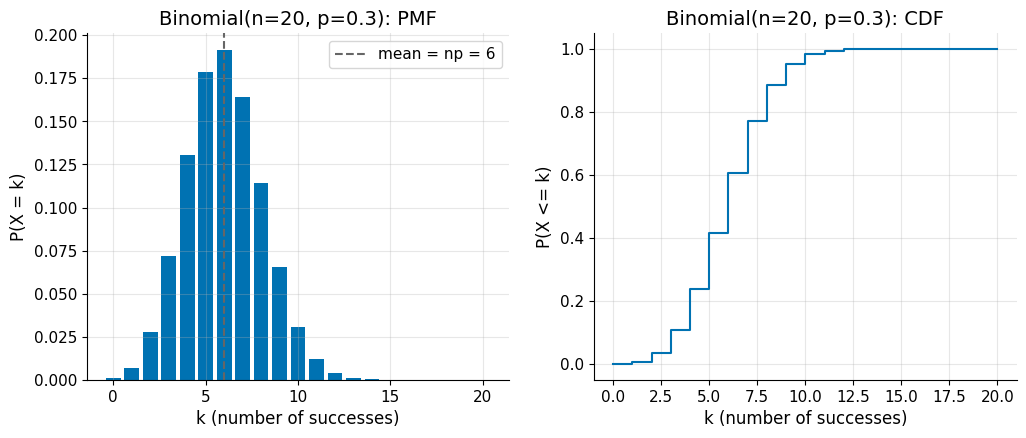

In [2]:
n = 20
p = 0.3
dist = stats.binom(n=n, p=p)
k_values = np.arange(0, n + 1)

fig, (ax_pmf, ax_cdf) = plt.subplots(1, 2, figsize=(12, 4.5))
ax_pmf.bar(k_values, dist.pmf(k_values), color=MAIN)
ax_pmf.axvline(dist.mean(), color=NEUTRAL, linestyle="--", label="mean = np = 6")
ax_pmf.set_title("Binomial(n=20, p=0.3): PMF")
ax_pmf.set_xlabel("k (number of successes)")
ax_pmf.set_ylabel("P(X = k)")
ax_pmf.legend()

ax_cdf.step(k_values, dist.cdf(k_values), where="post", color=MAIN)
ax_cdf.set_title("Binomial(n=20, p=0.3): CDF")
ax_cdf.set_xlabel("k (number of successes)")
ax_cdf.set_ylabel("P(X <= k)")
plt.show()

### 7.2 Effect of p
With n fixed at 30, small p gives a right-skewed shape, p = 0.5 is symmetric, large p is left-skewed.

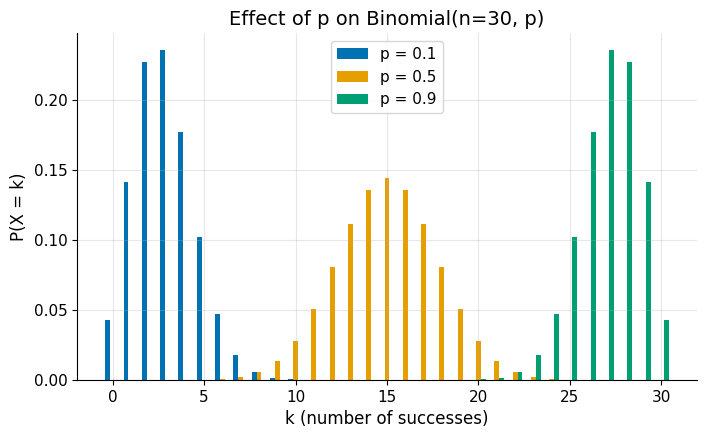

In [3]:
n = 30
k_values = np.arange(0, n + 1)
fig, ax = plt.subplots()
width = 0.27
for offset, p_value in zip([-width, 0, width], [0.1, 0.5, 0.9]):
    ax.bar(k_values + offset, stats.binom(n, p_value).pmf(k_values), width=width, label=f"p = {p_value}")
ax.set_title("Effect of p on Binomial(n=30, p)")
ax.set_xlabel("k (number of successes)")
ax.set_ylabel("P(X = k)")
ax.legend()
plt.show()

### 7.3 Effect of n
With p fixed at 0.3, growing n moves the center (mean np) and widens the spread, while the shape becomes more bell-like.

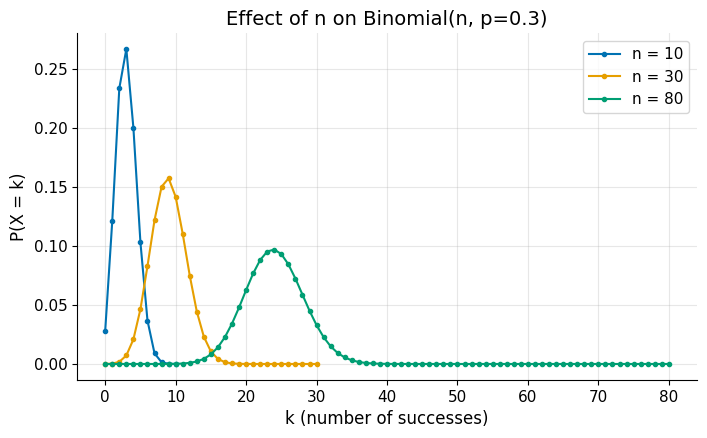

In [4]:
p = 0.3
fig, ax = plt.subplots()
for n_value, color in zip([10, 30, 80], COLORS):
    k_values = np.arange(0, n_value + 1)
    ax.plot(k_values, stats.binom(n_value, p).pmf(k_values), marker="o", markersize=3, color=color, label=f"n = {n_value}")
ax.set_title("Effect of n on Binomial(n, p=0.3)")
ax.set_xlabel("k (number of successes)")
ax.set_ylabel("P(X = k)")
ax.legend()
plt.show()

### 7.4 Normal approximation with continuity correction
The Binomial is discrete, the Normal is continuous. A bar at k covers the interval from k - 0.5 to k + 0.5, so $P(X\le k)\approx\Phi\big((k+0.5-np)/\sqrt{np(1-p)}\big)$. The +0.5 is the **continuity correction**.

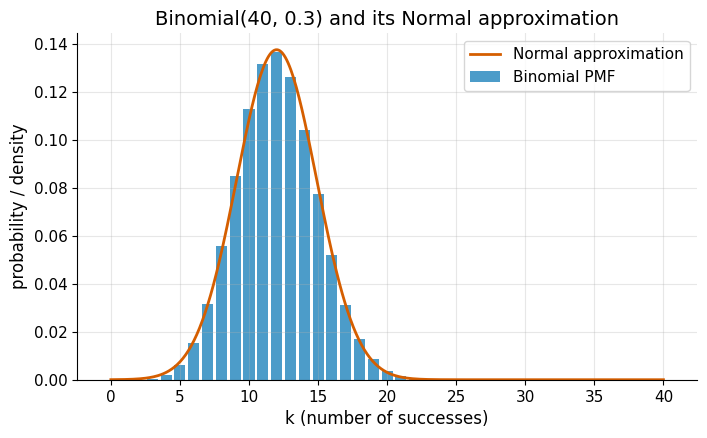

In [5]:
n = 40
p = 0.3
k_values = np.arange(0, n + 1)
normal_curve = stats.norm(loc=n * p, scale=np.sqrt(n * p * (1 - p)))

fig, ax = plt.subplots()
ax.bar(k_values, stats.binom(n, p).pmf(k_values), color=MAIN, alpha=0.7, label="Binomial PMF")
x_fine = np.linspace(0, n, 400)
ax.plot(x_fine, normal_curve.pdf(x_fine), color=HIGHLIGHT, linewidth=2, label="Normal approximation")
ax.set_title("Binomial(40, 0.3) and its Normal approximation")
ax.set_xlabel("k (number of successes)")
ax.set_ylabel("probability / density")
ax.legend()
plt.show()

In [6]:
k = 15
exact = stats.binom(n, p).cdf(k)
without_correction = normal_curve.cdf(k)
with_correction = normal_curve.cdf(k + 0.5)
print(f"P(X <= {k}) exact              = {exact:.5f}")
print(f"normal, no correction          = {without_correction:.5f}")
print(f"normal, continuity correction  = {with_correction:.5f}")

P(X <= 15) exact              = 0.88485
normal, no correction          = 0.84969
normal, continuity correction  = 0.88640


The corrected value is clearly closer to the exact one, so always use the correction when approximating a discrete variable by a Normal.

## 8. 3D visuals

### 8.1 Static: PMF over (k, p) for fixed n
For each p on the grid, a row of PMF values. The ridge follows the mean np.

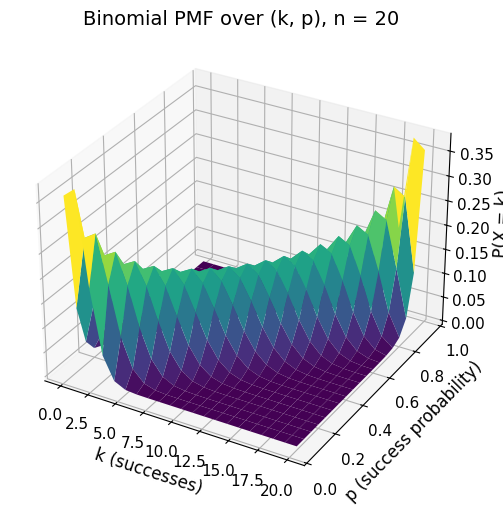

In [7]:
n = 20
k_values = np.arange(0, n + 1)
p_values = np.linspace(0.05, 0.95, 19)
K, P = np.meshgrid(k_values, p_values)
Z = stats.binom.pmf(K, n, P)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(K, P, Z, cmap="viridis", edgecolor="none")
ax.set_title("Binomial PMF over (k, p), n = 20")
ax.set_xlabel("k (successes)")
ax.set_ylabel("p (success probability)")
ax.set_zlabel("P(X = k)")
ax.view_init(elev=30, azim=-60)
plt.show()

### 8.2 Static: PMF over (k, n) for fixed p
Here p = 0.3 and n grows; the ridge moves right and flattens.

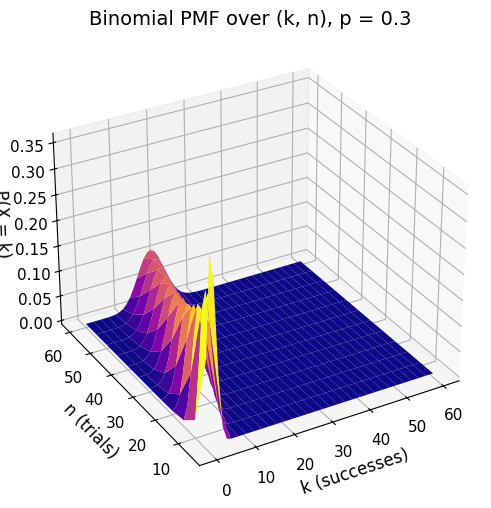

In [8]:
p = 0.3
n_values = np.arange(5, 61, 5)
k_values = np.arange(0, 61)
K, N = np.meshgrid(k_values, n_values)
Z = stats.binom.pmf(K, N, p)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(K, N, Z, cmap="plasma", edgecolor="none")
ax.set_title("Binomial PMF over (k, n), p = 0.3")
ax.set_xlabel("k (successes)")
ax.set_ylabel("n (trials)")
ax.set_zlabel("P(X = k)")
ax.view_init(elev=30, azim=-120)
plt.show()

### 8.3 Interactive Plotly version
Drag to rotate. The surface is the same as 8.1 but you can hover to read exact values.

In [9]:
n = 20
k_values = np.arange(0, n + 1)
p_values = np.linspace(0.05, 0.95, 37)
K, P = np.meshgrid(k_values, p_values)
Z = stats.binom.pmf(K, n, P)

fig = go.Figure(go.Surface(x=k_values, y=p_values, z=Z, colorscale="Viridis"))
fig.update_layout(title="Binomial PMF over (k, p), n = 20", width=750, height=550,
                  scene=dict(xaxis_title="k (successes)", yaxis_title="p", zaxis_title="P(X = k)"))
fig.show()

## 9. Simulation vs theory

### 9.1 Histogram against the PMF
We draw 10,000 samples from Binomial(20, 0.3) and compare the relative frequency of each value with the PMF.

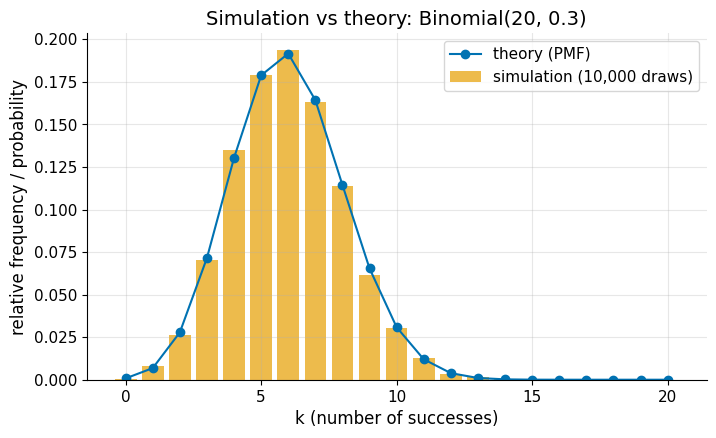

In [10]:
n = 20
p = 0.3
samples = rng.binomial(n=n, p=p, size=10_000)
k_values = np.arange(0, n + 1)
relative_freq = np.bincount(samples, minlength=n + 1) / len(samples)

fig, ax = plt.subplots()
ax.bar(k_values, relative_freq, color=SIM, alpha=0.7, label="simulation (10,000 draws)")
ax.plot(k_values, stats.binom(n, p).pmf(k_values), "o-", color=MAIN, label="theory (PMF)")
ax.set_title("Simulation vs theory: Binomial(20, 0.3)")
ax.set_xlabel("k (number of successes)")
ax.set_ylabel("relative frequency / probability")
ax.legend()
plt.show()

### 9.2 Running mean converges to np
The law of large numbers: the average of the first m samples approaches the true mean 6.

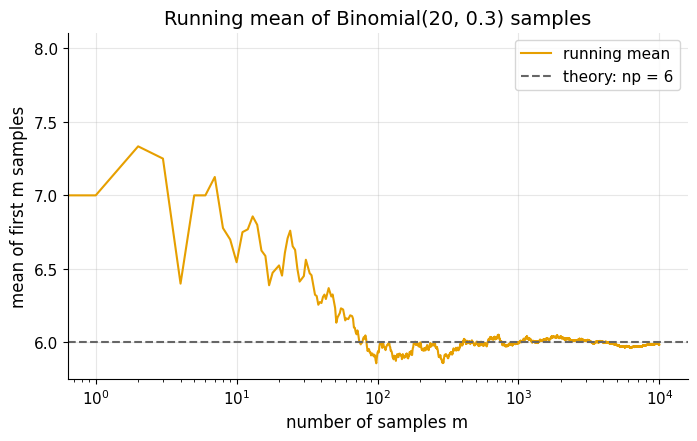

In [11]:
running_mean = np.cumsum(samples) / np.arange(1, len(samples) + 1)

fig, ax = plt.subplots()
ax.plot(running_mean, color=SIM, label="running mean")
ax.axhline(n * p, color=NEUTRAL, linestyle="--", label="theory: np = 6")
ax.set_title("Running mean of Binomial(20, 0.3) samples")
ax.set_xlabel("number of samples m")
ax.set_ylabel("mean of first m samples")
ax.set_xscale("log")
ax.legend()
plt.show()

## 10. `scipy.stats` cheat sheet

A frozen object `stats.binom(n, p)` carries the parameters. Each method answers a different question.

In [12]:
dist = stats.binom(n=20, p=0.3)
print("pmf(6)       P(X = 6)          :", round(dist.pmf(6), 5))
print("cdf(6)       P(X <= 6)         :", round(dist.cdf(6), 5))
print("sf(6)        P(X > 6)          :", round(dist.sf(6), 5))
print("ppf(0.9)     smallest k with cdf >= 0.9:", dist.ppf(0.9))
print("rvs(5)       5 random draws    :", dist.rvs(size=5, random_state=1))
print("mean, var    :", dist.mean(), dist.var())
print("interval(0.95) central 95% range:", dist.interval(0.95))
print("stats        mean, var, skew, kurt:", dist.stats(moments="mvsk"))

pmf(6)       P(X = 6)          : 0.19164
cdf(6)       P(X <= 6)         : 0.60801
sf(6)        P(X > 6)          : 0.39199
ppf(0.9)     smallest k with cdf >= 0.9: 9.0
rvs(5)       5 random draws    : [6 7 0 5 4]
mean, var    : 6.0 4.2
interval(0.95) central 95% range: (np.float64(2.0), np.float64(10.0))
stats        mean, var, skew, kurt: (np.float64(6.0), np.float64(4.2), np.float64(0.19518001458970663), np.float64(-0.06190476190476191))


**Fitting:** the MLE of p given known n and observed counts is simply total successes divided by total trials. `scipy` does not fit the Binomial with `fit`, so we do it directly.

In [13]:
daily_orders = rng.binomial(n=1000, p=0.032, size=60)
p_hat = daily_orders.sum() / (1000 * len(daily_orders))
print(f"true p = 0.032, estimated p = {p_hat:.4f}")

true p = 0.032, estimated p = 0.0330


## 11. Real-world worked example: an online store

**Scenario (illustrative numbers).** An online store gets **1,000 visitors per day**. Historically **3.2 %** of visitors place an order. Treat each visitor as an independent Bernoulli trial, so daily orders $X\sim\text{Bin}(1000,\,0.032)$.

**Questions**
1. What is the expected number of orders and its standard deviation?
2. What is $P(X\ge 45)$, a "great day"?
3. What is $P(25\le X\le 40)$, a "normal day"?
4. How many orders should we plan inventory for so that a stock-out happens on only 5 % of days?

### 11.1 By hand
**Q1.** $E[X]=np=1000\times0.032=32$. $\mathrm{Var}(X)=np(1-p)=32\times0.968=30.976$, so $\mathrm{SD}=\sqrt{30.976}\approx5.566$.

**Q2.** $P(X\ge45)=1-P(X\le44)=1-\sum_{k=0}^{44}\binom{1000}{k}0.032^k\,0.968^{1000-k}$. Summing 45 terms on paper is tedious, so first the normal approximation with continuity correction:
$$z=\frac{44.5-32}{5.566}=2.246,\qquad P(X\ge45)\approx1-\Phi(2.246)\approx1-0.9877=0.0123.$$

**Q3.** $P(25\le X\le40)=F(40)-F(24)$. Normal approximation: $z_{hi}=\frac{40.5-32}{5.566}=1.527$ and $z_{lo}=\frac{24.5-32}{5.566}=-1.347$, so $\Phi(1.527)-\Phi(-1.347)\approx0.9366-0.0890=0.8476$.

**Q4.** We need the smallest $c$ with $P(X>c)\le0.05$, that is $F(c)\ge0.95$. Normal: $c\approx32+1.645\times5.566=41.2$, so about 41 or 42 (the exact quantile is found in code).

The next cell does the *exact* hand formula: the PMF written out as an explicit sum with `math.comb`, no `scipy`.

In [14]:
import math

n_visitors = 1000
p_conversion = 0.032

def pmf_by_formula(k):
    # C(n, k) * p^k * (1-p)^(n-k), exactly as written in the definition
    return math.comb(n_visitors, k) * p_conversion**k * (1 - p_conversion)**(n_visitors - k)

p_at_least_45_hand = 1 - sum(pmf_by_formula(k) for k in range(0, 45))
p_25_to_40_hand = sum(pmf_by_formula(k) for k in range(25, 41))
print(f"hand formula: P(X >= 45)       = {p_at_least_45_hand:.5f}")
print(f"hand formula: P(25 <= X <= 40) = {p_25_to_40_hand:.5f}")

hand formula: P(X >= 45)       = 0.01577
hand formula: P(25 <= X <= 40) = 0.84796


### 11.2 In code with `scipy`, and the assert
The frozen distribution gives the same numbers in one call each. The `assert` lines check that hand and code agree.

In [15]:
store = stats.binom(n=n_visitors, p=p_conversion)

p_at_least_45_code = store.sf(44)                   # sf(44) = P(X > 44) = P(X >= 45)
p_25_to_40_code = store.cdf(40) - store.cdf(24)
stock_level = store.ppf(0.95)                       # smallest c with P(X <= c) >= 0.95

assert np.isclose(p_at_least_45_hand, p_at_least_45_code)
assert np.isclose(p_25_to_40_hand, p_25_to_40_code)
print(f"mean = {store.mean():.1f}, sd = {store.std():.3f}")
print(f"P(X >= 45)       = {p_at_least_45_code:.5f}")
print(f"P(25 <= X <= 40) = {p_25_to_40_code:.5f}")
print(f"inventory level (95th percentile) = {stock_level:.0f}")

mean = 32.0, sd = 5.566
P(X >= 45)       = 0.01577
P(25 <= X <= 40) = 0.84796
inventory level (95th percentile) = 41


The inventory quantile is checked directly: stocking `stock_level` units leaves at most 5 % of days with a stock-out, and one unit less would not.

In [16]:
assert store.sf(stock_level) <= 0.05
assert store.sf(stock_level - 1) > 0.05
print(f"P(stock-out) when stocking {stock_level:.0f} units = {store.sf(stock_level):.4f}")

P(stock-out) when stocking 41 units = 0.0484


### 11.3 Verify by simulation
Simulate 10,000 days, count the days with at least 45 orders and the days in the normal range, and compare with the exact answers.

In [17]:
simulated_orders = rng.binomial(n=n_visitors, p=p_conversion, size=10_000)

sim_at_least_45 = np.mean(simulated_orders >= 45)
sim_25_to_40 = np.mean((simulated_orders >= 25) & (simulated_orders <= 40))
sim_stockout = np.mean(simulated_orders > stock_level)

print(f"P(X >= 45):       exact {p_at_least_45_code:.4f}  simulated {sim_at_least_45:.4f}")
print(f"P(25 <= X <= 40): exact {p_25_to_40_code:.4f}  simulated {sim_25_to_40:.4f}")
print(f"P(stock-out):     exact {store.sf(stock_level):.4f}  simulated {sim_stockout:.4f}")
assert abs(sim_at_least_45 - p_at_least_45_code) < 0.005
assert abs(sim_25_to_40 - p_25_to_40_code) < 0.02

P(X >= 45):       exact 0.0158  simulated 0.0172
P(25 <= X <= 40): exact 0.8480  simulated 0.8457
P(stock-out):     exact 0.0484  simulated 0.0448


### 11.4 Plots with the regions shaded
Three views of the same distribution: the great-day tail, the normal-day band, and the inventory cut-off.

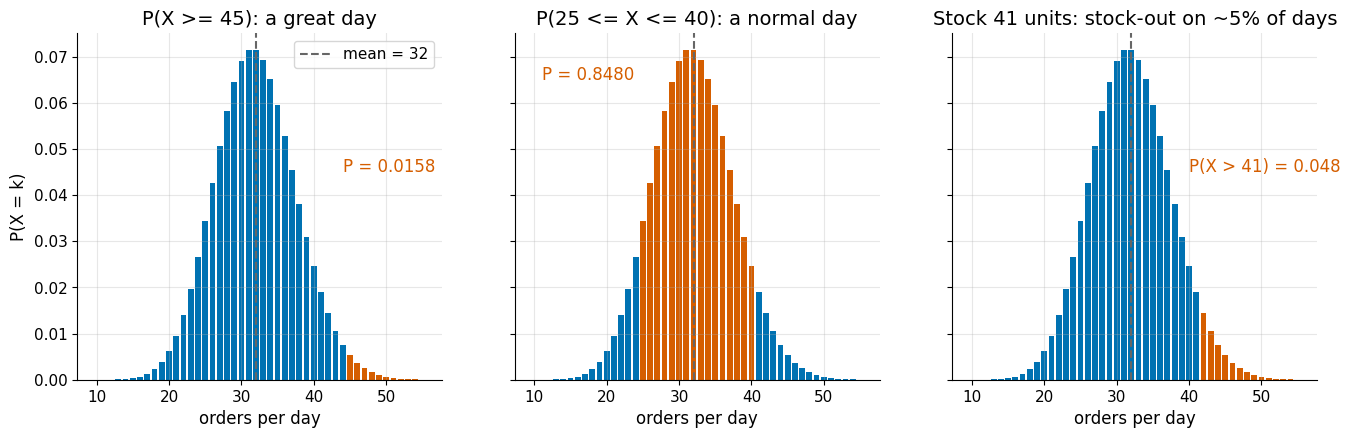

In [18]:
k_values = np.arange(10, 56)
pmf_values = store.pmf(k_values)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

# Panel 1: P(X >= 45)
axes[0].bar(k_values, pmf_values, color=MAIN)
tail = k_values >= 45
axes[0].bar(k_values[tail], pmf_values[tail], color=HIGHLIGHT)
axes[0].set_title("P(X >= 45): a great day")
axes[0].text(44, 0.045, f"P = {p_at_least_45_code:.4f}", color=HIGHLIGHT, fontsize=12)

# Panel 2: P(25 <= X <= 40)
axes[1].bar(k_values, pmf_values, color=MAIN)
band = (k_values >= 25) & (k_values <= 40)
axes[1].bar(k_values[band], pmf_values[band], color=HIGHLIGHT)
axes[1].set_title("P(25 <= X <= 40): a normal day")
axes[1].text(11, 0.065, f"P = {p_25_to_40_code:.4f}", color=HIGHLIGHT, fontsize=12)

# Panel 3: inventory level
axes[2].bar(k_values, pmf_values, color=MAIN)
over = k_values > stock_level
axes[2].bar(k_values[over], pmf_values[over], color=HIGHLIGHT)
axes[2].set_title(f"Stock {stock_level:.0f} units: stock-out on ~5% of days")
axes[2].text(40, 0.045, f"P(X > {stock_level:.0f}) = {store.sf(stock_level):.3f}", color=HIGHLIGHT, fontsize=12)

for ax in axes:
    ax.axvline(store.mean(), color=NEUTRAL, linestyle="--", label="mean = 32")
    ax.set_xlabel("orders per day")
axes[0].set_ylabel("P(X = k)")
axes[0].legend()
plt.show()

The simulation as a histogram of the 10,000 simulated days, overlaid with the exact PMF and the inventory cut-off.

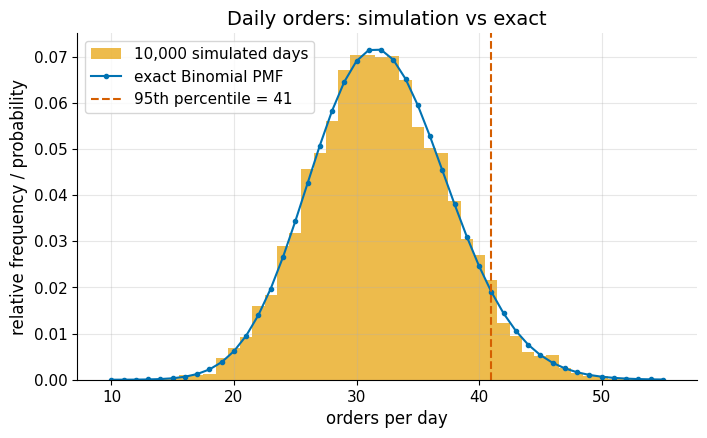

In [19]:
fig, ax = plt.subplots()
ax.hist(simulated_orders, bins=np.arange(10, 57) - 0.5, density=True, color=SIM, alpha=0.7, label="10,000 simulated days")
ax.plot(k_values, pmf_values, "o-", color=MAIN, markersize=3, label="exact Binomial PMF")
ax.axvline(stock_level, color=HIGHLIGHT, linestyle="--", label=f"95th percentile = {stock_level:.0f}")
ax.set_title("Daily orders: simulation vs exact")
ax.set_xlabel("orders per day")
ax.set_ylabel("relative frequency / probability")
ax.legend()
plt.show()

### 11.5 Interpretation and decision
- On a typical day the store gets about **32 orders**, give or take 5 or 6.
- A day with **45 or more orders is rare** (about 1 day in 60), so it should not be used to judge a marketing change by itself.
- About **85 % of days** fall between 25 and 40 orders.
- **Decision:** to risk a stock-out on only 5 % of days, **stock enough for the 95th-percentile number of orders printed above (about 41)**. Planning for the average of 32 would run out on roughly half of the days.

### 11.6 Second example: quality control
A packing line makes boxes of 50 items with a **2 % defect rate** (illustrative). What is the probability that a box has **3 or more** defects?
$P(X\ge3)=1-[P(0)+P(1)+P(2)]$ with $X\sim\text{Bin}(50,0.02)$.

In [20]:
box = stats.binom(n=50, p=0.02)
p_by_hand = 1 - (0.98**50 + 50 * 0.02 * 0.98**49 + math.comb(50, 2) * 0.02**2 * 0.98**48)
p_by_code = box.sf(2)
assert np.isclose(p_by_hand, p_by_code)
print(f"P(box has >= 3 defects) = {p_by_code:.4f}  (about 1 box in {1 / p_by_code:.0f})")

P(box has >= 3 defects) = 0.0784  (about 1 box in 13)


## 12. Where it is used

### Statistics
- **A/B testing:** conversions in each arm are Binomial counts; the test compares two proportions.
- **Confidence intervals for a proportion** (poll results, defect rates) come from the Binomial or its Normal approximation.
- **Sign test:** under the null, the number of positive differences is Binomial(n, 0.5).

### Data science
- Click-through and conversion rates, churn counts per cohort and spam counts per day are Binomial counts.
- Proportion dashboards need the standard error $\sqrt{p(1-p)/n}$ to know when a change is noise.

### ML and AI
- **Binary labels and logistic regression:** each label is Bernoulli($p_i$), and the log-loss is the negative Bernoulli log-likelihood.
- **Dropout:** each unit is kept with a Bernoulli mask.
- **Ensembles:** majority voting of n independent classifiers, each correct with probability p, follows a Binomial tail.

## 13. Common pitfalls and misconceptions

- **Dependence:** if visitors are not independent (a viral post, shared sessions), the variance is larger than np(1-p) and Binomial probabilities are too optimistic.
- **Varying p:** if p differs across trials (mobile vs desktop), the sum is *not* Binomial; its variance is smaller than np(1-p) with the average p.
- **Off-by-one:** `P(X >= 45)` is `sf(44)`, not `sf(45)`. `cdf(k)` includes k.
- **Normal approximation without continuity correction** biases tail probabilities, and it fails when np or n(1-p) is small (use the exact Binomial or a Poisson).
- **Mean is not the plan:** planning stock at the mean leaves a stock-out about half the time.

## 14. Exercises

1. A fair coin is tossed 10 times. What is the probability of exactly 5 heads?
2. A multiple-choice quiz has 12 questions with 4 options each. A student guesses every answer. What is P(at least 6 correct)?
3. Show that $\mathrm{Var}(X)$ of a Binomial(n, p) is largest for $p=0.5$, and find the maximum for $n=100$.
4. A server fails a health check with probability 0.01 per check, independently. In 200 checks, what is the probability of at least one failure? How many failures do we expect, and what is the standard deviation?
5. Using code, find the smallest n for which P(at least 1 success) is at least 0.99 when p = 0.05.
6. For Binomial(100, 0.4), compute P(35 <= X <= 45) exactly and with the normal approximation (with and without continuity correction). Which is closer?
7. (Harder) Two independent stores have Bin(300, 0.04) and Bin(500, 0.04) orders. Name the distribution of the total and compute P(total >= 40). Why must both p values be equal?
8. (Harder) Derive the PGF of Binomial(n, p), use it to compute $E[X(X-1)]$, then recover $\mathrm{Var}(X)$.

Solutions are at the end of the notebook.

## 15. Summary table

| Item | Value |
|---|---|
| Parameters | n (trials, integer >= 1), p (success probability, 0 to 1) |
| Support | k = 0, 1, ..., n |
| PMF | C(n,k) p^k (1-p)^(n-k) |
| Mean | np |
| Variance | np(1-p) |
| Skewness | (1-2p) / sqrt(np(1-p)) |
| When to use | count of successes in a fixed number of independent, identical yes/no trials |
| `scipy` name | `scipy.stats.binom(n, p)`; Bernoulli is `scipy.stats.bernoulli(p)` |

## Solutions

In [21]:
print("1:", stats.binom(10, 0.5).pmf(5))
print("2:", stats.binom(12, 0.25).sf(5))           # P(X >= 6) = sf(5)
print("4: P(>=1 failure) =", 1 - 0.99**200, " mean =", 200 * 0.01, " sd =", np.sqrt(200 * 0.01 * 0.99))

n_needed = int(np.ceil(np.log(0.01) / np.log(0.95)))
print("5: n =", n_needed, " check:", 1 - 0.95**n_needed)

d = stats.binom(100, 0.4)
approx = stats.norm(d.mean(), d.std())
exact = d.cdf(45) - d.cdf(34)
no_corr = approx.cdf(45) - approx.cdf(35)
with_corr = approx.cdf(45.5) - approx.cdf(34.5)
print(f"6: exact {exact:.4f}, no correction {no_corr:.4f}, with correction {with_corr:.4f}")

total = stats.binom(800, 0.04)
print("7: P(total >= 40) =", total.sf(39))

1: 0.24609375
2: 0.05440223217010498
4: P(>=1 failure) = 0.8660203251420383  mean = 2.0  sd = 1.407124727947029
5: n = 90  check: 0.9901116352903411
6: exact 0.7386, no correction 0.6926, with correction 0.7384
7: P(total >= 40) = 0.0911649009902305


**1.** $\binom{10}{5}/2^{10}=252/1024\approx0.2461$ (matches the printed value).

**2.** Printed above: guessing rarely reaches 6 of 12.

**3.** $\mathrm{Var}=np(1-p)$ and $p(1-p)$ has derivative $1-2p$, which is zero at $p=0.5$ (a maximum). For $n=100$ the maximum is $100\times0.25=25$ (SD 5).

**4.** $P(\ge1)=1-0.99^{200}\approx0.866$, mean 2, SD about 1.407.

**5.** $1-0.95^n\ge0.99\Rightarrow n\ge\ln0.01/\ln0.95\approx89.8$, so $n=90$.

**6.** The version with continuity correction is closer to the exact value.

**7.** The total is Bin(800, 0.04). The PGFs multiply to $(1-p+ps)^{300}(1-p+ps)^{500}=(1-p+ps)^{800}$, which only combines into one power when both $p$ are equal.

**8.** $G(s)=(1-p+ps)^n$, so $G''(1)=n(n-1)p^2=E[X(X-1)]$. Then $\mathrm{Var}(X)=E[X(X-1)]+E[X]-E[X]^2=n(n-1)p^2+np-n^2p^2=np-np^2=np(1-p)$.